In [ ]:
from google.colab import files
uploaded = files.upload()


KeyboardInterrupt: 

In [ ]:
# Install necessary libraries (if not already installed)
!pip install scikit-learn pandas numpy


In [ ]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report


In [ ]:
# Load dataset (Update path if using Google Drive)
df = pd.read_csv("/content/IMDB Dataset.csv")  # Adjust path accordingly

# Convert 'sentiment' to numerical labels: Positive -> 1 (Genuine), Negative -> 0 (Fake)
df['sentiment_label'] = df['sentiment'].map({'positive': 1, 'negative': 0})

# Downsample dataset to 10,000 reviews for efficiency
df_sampled = df.sample(n=10000, random_state=42)


In [ ]:
# Convert text to numerical features using TF-IDF (max 300 words)
vectorizer = TfidfVectorizer(stop_words="english", max_features=300)
tfidf_matrix = vectorizer.fit_transform(df_sampled["review"].astype(str))


In [ ]:
# Split data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(tfidf_matrix, df_sampled['sentiment_label'], test_size=0.2, random_state=42)


In [ ]:
# Initialize and train Logistic Regression model
log_reg = LogisticRegression(max_iter=1000, solver='liblinear', random_state=42)
log_reg.fit(X_train, y_train)

# Make predictions
y_pred_logreg = log_reg.predict(X_test)

# Evaluate the model
accuracy_logreg = accuracy_score(y_test, y_pred_logreg)
classification_rep_logreg = classification_report(y_test, y_pred_logreg)

print(" Logistic Regression Accuracy:", accuracy_logreg)
print(" Classification Report:\n", classification_rep_logreg)


✅ Logistic Regression Accuracy: 0.816
✅ Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.79      0.81       999
           1       0.80      0.84      0.82      1001

    accuracy                           0.82      2000
   macro avg       0.82      0.82      0.82      2000
weighted avg       0.82      0.82      0.82      2000



In [ ]:
# Save TF-IDF matrix to CSV
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=vectorizer.get_feature_names_out())
tfidf_df.to_csv("tfidf_results.csv", index=False)

# Save Logistic Regression Predictions
df_logreg_results = pd.DataFrame({
    "Actual Label": y_test.values,
    "Predicted Label": y_pred_logreg
})
df_logreg_results.to_csv("logreg_predictions.csv", index=False)

print("✅ Results saved successfully!")


✅ Results saved successfully!


In [ ]:
def predict_review(review_text):
    # Transform the user input using the trained TF-IDF vectorizer
    review_tfidf = vectorizer.transform([review_text])

    # Predict the sentiment (0 = Fake, 1 = Genuine)
    prediction = log_reg.predict(review_tfidf)[0]

    # Display result
    if prediction == 1:
        return "This review is Genuine!"
    else:
        return " This review is Fake!"


In [ ]:
# Get a review from the user
user_review = input("Enter a review: ")

# Predict and print the result
print(predict_review(user_review))


Enter a review: this is a god product


NameError: name 'predict_review' is not defined

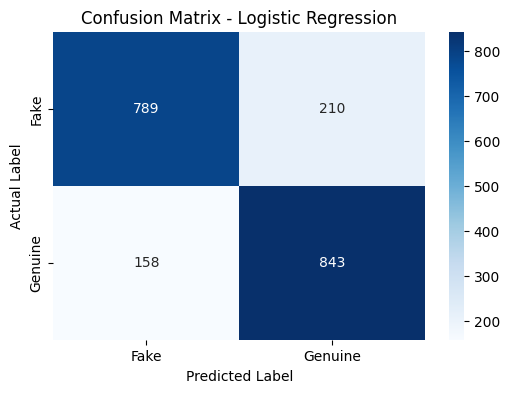

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred_logreg)

# Plot confusion matrix as heatmap
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Fake", "Genuine"], yticklabels=["Fake", "Genuine"])
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()


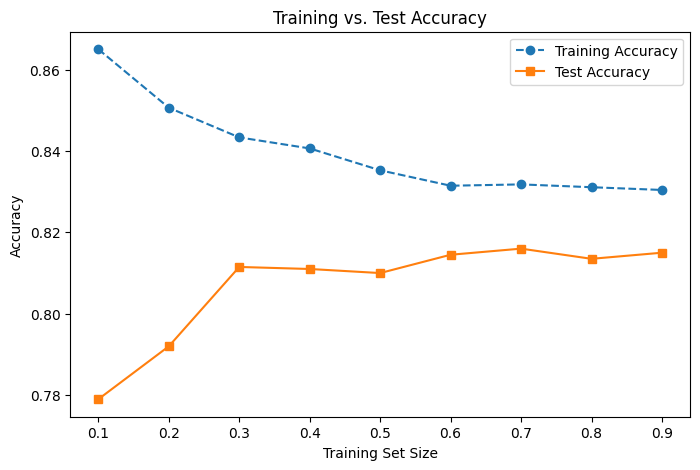

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# Define training sizes (avoid 1.0 to prevent error)
train_sizes = np.linspace(0.1, 0.9, 9)

# Store accuracy scores
train_accuracies = []
test_accuracies = []

for size in train_sizes:
    X_train_sub, _, y_train_sub, _ = train_test_split(X_train, y_train, train_size=size, random_state=42)
    model = LogisticRegression(max_iter=1000, solver='liblinear', random_state=42)
    model.fit(X_train_sub, y_train_sub)
    train_accuracies.append(model.score(X_train_sub, y_train_sub))
    test_accuracies.append(model.score(X_test, y_test))

# Plot training vs. test accuracy
plt.figure(figsize=(8,5))
plt.plot(train_sizes, train_accuracies, marker='o', linestyle='--', label="Training Accuracy")
plt.plot(train_sizes, test_accuracies, marker='s', linestyle='-', label="Test Accuracy")
plt.xlabel("Training Set Size")
plt.ylabel("Accuracy")
plt.title("Training vs. Test Accuracy")
plt.legend()
plt.show()


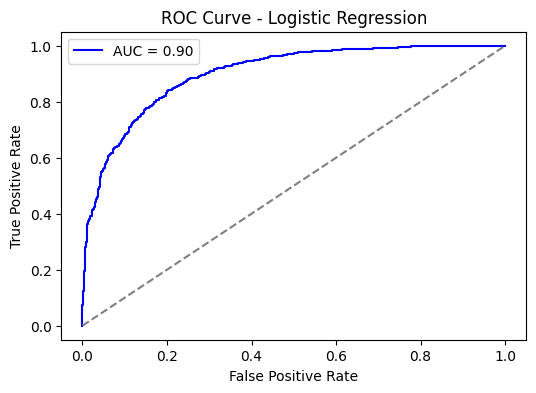

In [ ]:
from sklearn.metrics import roc_curve, auc

# Get ROC curve values
fpr, tpr, _ = roc_curve(y_test, log_reg.predict_proba(X_test)[:,1])
roc_auc = auc(fpr, tpr)

# Plot ROC Curve
plt.figure(figsize=(6,4))
plt.plot(fpr, tpr, color="blue", label="AUC = {:.2f}".format(roc_auc))
plt.plot([0,1], [0,1], linestyle="--", color="gray")  # Random guess line
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.show()


<ipython-input-25-acf72c5678ea>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df_sampled["sentiment_label"], palette="pastel")


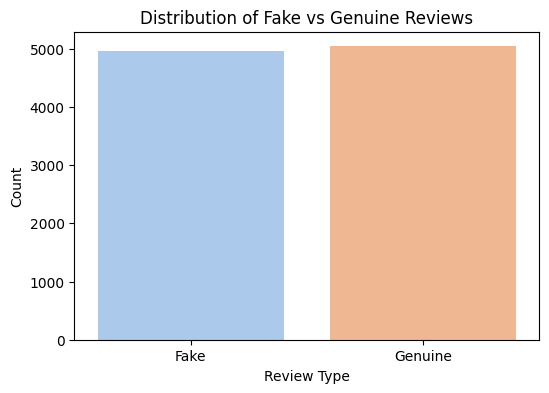

In [ ]:
# Count plot of Genuine (1) vs Fake (0) Reviews
plt.figure(figsize=(6,4))
sns.countplot(x=df_sampled["sentiment_label"], palette="pastel")
plt.xticks(ticks=[0,1], labels=["Fake", "Genuine"])
plt.xlabel("Review Type")
plt.ylabel("Count")
plt.title("Distribution of Fake vs Genuine Reviews")
plt.show()
